#1. Setup + FP16 cache

In [2]:
# Install dependencies
!pip -q install -U transformers accelerate safetensors

import torch
import pandas as pd
import numpy as np
import math

from transformers import AutoTokenizer, AutoModelForCausalLM


# --------------------------------------------------
# Configuration
# --------------------------------------------------

MODEL_ID = "Qwen/Qwen2.5-1.5B"
DTYPE = torch.float16

ANALYSIS_SEQ_LEN = 2048
PAGE_SIZE = 16


# --------------------------------------------------
# GPU
# --------------------------------------------------

print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU runtime required.")

gpu = torch.cuda.get_device_properties(0)

print("GPU:", gpu.name)
print(f"VRAM: {gpu.total_memory / 1024**3:.2f} GiB")


# --------------------------------------------------
# Load model
# --------------------------------------------------

print("\nLoading:", MODEL_ID)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
    device_map={"": 0},
    low_cpu_mem_usage=True,
    attn_implementation="sdpa",
)

model.eval()


# --------------------------------------------------
# Architecture
# --------------------------------------------------

config = model.config

num_layers = config.num_hidden_layers
num_attention_heads = config.num_attention_heads

num_kv_heads = getattr(
    config,
    "num_key_value_heads",
    num_attention_heads
)

hidden_size = config.hidden_size

head_dim = getattr(
    config,
    "head_dim",
    hidden_size // num_attention_heads
)


# --------------------------------------------------
# Create 2048-token sequence
# --------------------------------------------------

text = (
    "Large language models generate text autoregressively. "
    "During generation, attention layers reuse previously computed "
    "key and value vectors through the KV cache. "
    "Efficient KV-cache management becomes increasingly important "
    "as the context length grows. "
) * 500

input_ids = tokenizer(
    text,
    return_tensors="pt",
    add_special_tokens=False
).input_ids[:, :ANALYSIS_SEQ_LEN]

input_ids = input_ids.to(model.device)


# --------------------------------------------------
# Build FP16 KV cache
# --------------------------------------------------

with torch.inference_mode():
    outputs = model(
        input_ids=input_ids,
        use_cache=True
    )

fp16_cache = outputs.past_key_values


# --------------------------------------------------
# Basic validation
# --------------------------------------------------

key0 = fp16_cache.layers[0].keys
value0 = fp16_cache.layers[0].values

print("\nInput shape:", tuple(input_ids.shape))
print("Number of layers:", len(fp16_cache.layers))
print("Cache sequence length:", fp16_cache.get_seq_length())

print("\nLayer 0 K:", tuple(key0.shape), key0.dtype)
print("Layer 0 V:", tuple(value0.shape), value0.dtype)

print("\nPage size:", PAGE_SIZE)
print(
    "Number of logical pages:",
    math.ceil(ANALYSIS_SEQ_LEN / PAGE_SIZE)
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 115.4 MB/s eta 0:00:00
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GiB

Loading: Qwen/Qwen2.5-1.5B


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]


Input shape: (1, 2048)
Number of layers: 28
Cache sequence length: 2048

Layer 0 K: (1, 2, 2048, 128) torch.float16
Layer 0 V: (1, 2, 2048, 128) torch.float16

Page size: 16
Number of logical pages: 128


#2. Symmetric quantization functions

### Symmetric Uniform Quantization

We use symmetric uniform quantization to compress KV-cache tensors from FP16 to lower-bit integer representations. For a tensor $x$, a single scale factor is computed from its maximum absolute value:

$$s = \frac{\max |x|}{q_{\max}}$$

where

$$q_{\max} = 2^{b-1} - 1$$

for a $b$-bit representation. Each floating-point value is quantized as

$$q = \text{clip}\left(\text{round}\left(\frac{x}{s}\right), -q_{\max}, q_{\max}\right)$$

and reconstructed using

$$\hat{x} = s \cdot q$$

Because the quantization range is symmetric around zero, no zero-point is required. INT8 uses the range $[-127, 127]$, while our symmetric INT4 representation uses $[-7, 7]$. Lower bit-widths reduce KV-cache memory but introduce larger quantization error.

In this project, the same method will later be applied independently to individual KV-cache pages, allowing different pages to use different precisions.

In [3]:
# --------------------------------------------------
# Symmetric quantization / dequantization
# --------------------------------------------------

def symmetric_quantize(tensor, num_bits):
    """
    Symmetric per-tensor quantization.

    Parameters
    ----------
    tensor : torch.Tensor
        FP16 / FP32 tensor to quantize.

    num_bits : int
        Supported values: 8 or 4.

    Returns
    -------
    q_tensor : torch.Tensor
        Quantized integer values.

    scale : torch.Tensor
        Scale used for reconstruction.
    """

    if num_bits not in [4, 8]:
        raise ValueError("Only INT4 and INT8 are supported.")

    # Symmetric integer range
    qmax = (2 ** (num_bits - 1)) - 1
    qmin = -qmax

    # Work in FP32 while calculating the scale
    tensor_fp32 = tensor.float()

    max_abs = tensor_fp32.abs().max()

    # Avoid division by zero for an all-zero tensor
    if max_abs == 0:
        scale = torch.tensor(
            1.0,
            device=tensor.device,
            dtype=torch.float32
        )
    else:
        scale = max_abs / qmax

    # FP -> integer
    q_tensor = torch.round(
        tensor_fp32 / scale
    )

    q_tensor = torch.clamp(
        q_tensor,
        qmin,
        qmax
    )

    # int8 is used as the physical container for now.
    # For INT4, only values [-7, 7] are used.
    q_tensor = q_tensor.to(torch.int8)

    return q_tensor, scale


def symmetric_dequantize(q_tensor, scale, dtype=torch.float16):
    """
    Reconstruct an approximate floating-point tensor.
    """

    reconstructed = (
        q_tensor.float() * scale
    )

    return reconstructed.to(dtype)

In [4]:
# --------------------------------------------------
# Small sanity check
# --------------------------------------------------

toy_tensor = torch.tensor(
    [-1.0, -0.5, 0.0, 0.5, 1.0],
    device=model.device,
    dtype=torch.float16
)

print("Original:")
print(toy_tensor)


# INT8
q8, scale8 = symmetric_quantize(
    toy_tensor,
    num_bits=8
)

dq8 = symmetric_dequantize(
    q8,
    scale8
)


print("\nINT8")
print("Scale:", scale8.item())
print("Quantized:", q8)
print("Reconstructed:", dq8)


# INT4
q4, scale4 = symmetric_quantize(
    toy_tensor,
    num_bits=4
)

dq4 = symmetric_dequantize(
    q4,
    scale4
)


print("\nINT4")
print("Scale:", scale4.item())
print("Quantized:", q4)
print("Reconstructed:", dq4)

Original:
tensor([-1.0000, -0.5000,  0.0000,  0.5000,  1.0000], device='cuda:0',
       dtype=torch.float16)

INT8
Scale: 0.007874015718698502
Quantized: tensor([-127,  -64,    0,   64,  127], device='cuda:0', dtype=torch.int8)
Reconstructed: tensor([-1.0000, -0.5039,  0.0000,  0.5039,  1.0000], device='cuda:0',
       dtype=torch.float16)

INT4
Scale: 0.1428571492433548
Quantized: tensor([-7, -3,  0,  3,  7], device='cuda:0', dtype=torch.int8)
Reconstructed: tensor([-1.0000, -0.4285,  0.0000,  0.4285,  1.0000], device='cuda:0',
       dtype=torch.float16)


Expected: INT8 error < INT4 error

This output already demonstrates the expected tradeoff:

INT8 preserves values more accurately than INT4
	​


while:

INT4 has greater theoretical memory savings
	​


#3. Apply INT8 to a real KV page

Here the three error metrics mean:

$$\text{MAE} = \frac{1}{N} \sum_{i} |x_i - \hat{x}_i|$$

is the average absolute quantization error.

$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i} (x_i - \hat{x}_i)^2}$$

penalizes larger errors more heavily.

And

$$\text{Max Error} = \max_{i} |x_i - \hat{x}_i|$$

shows the worst reconstructed value in that page.

In [5]:
# --------------------------------------------------
# Extract Page 0 from Layer 0
# --------------------------------------------------

layer_idx = 0
page_idx = 0

start_token = page_idx * PAGE_SIZE
end_token = start_token + PAGE_SIZE

key_page = fp16_cache.layers[layer_idx].keys[
    :, :, start_token:end_token, :
]

value_page = fp16_cache.layers[layer_idx].values[
    :, :, start_token:end_token, :
]


print("K page shape:", tuple(key_page.shape))
print("V page shape:", tuple(value_page.shape))


# --------------------------------------------------
# Quantize to INT8
# --------------------------------------------------

q_key_int8, key_scale_int8 = symmetric_quantize(
    key_page,
    num_bits=8
)

q_value_int8, value_scale_int8 = symmetric_quantize(
    value_page,
    num_bits=8
)


# --------------------------------------------------
# Dequantize back to FP16
# --------------------------------------------------

dq_key_int8 = symmetric_dequantize(
    q_key_int8,
    key_scale_int8
)

dq_value_int8 = symmetric_dequantize(
    q_value_int8,
    value_scale_int8
)


# --------------------------------------------------
# Error measurement
# --------------------------------------------------

def quantization_error(original, reconstructed):

    diff = (
        original.float() -
        reconstructed.float()
    )

    mae = diff.abs().mean().item()

    rmse = torch.sqrt(
        (diff ** 2).mean()
    ).item()

    max_error = diff.abs().max().item()

    return mae, rmse, max_error


key_mae8, key_rmse8, key_max8 = quantization_error(
    key_page,
    dq_key_int8
)

value_mae8, value_rmse8, value_max8 = quantization_error(
    value_page,
    dq_value_int8
)


# --------------------------------------------------
# Results
# --------------------------------------------------

print("\nINT8 Scales")
print("K scale:", key_scale_int8.item())
print("V scale:", value_scale_int8.item())

print("\nKey Quantization Error")
print(f"MAE:       {key_mae8:.8f}")
print(f"RMSE:      {key_rmse8:.8f}")
print(f"Max error: {key_max8:.8f}")

print("\nValue Quantization Error")
print(f"MAE:       {value_mae8:.8f}")
print(f"RMSE:      {value_rmse8:.8f}")
print(f"Max error: {value_max8:.8f}")

K page shape: (1, 2, 16, 128)
V page shape: (1, 2, 16, 128)

INT8 Scales
K scale: 2.503937005996704
V scale: 0.028312623500823975

Key Quantization Error
MAE:       0.61359715
RMSE:      0.71222132
Max error: 1.25195312

Value Quantization Error
MAE:       0.00708008
RMSE:      0.00818890
Max error: 0.01416016


INT8 Quantization of a Real KV Page

Applying symmetric INT8 quantization to the first KV-cache page revealed substantially different numerical ranges for Keys and Values. The Key tensor used a scale of approximately 2.504, corresponding to a maximum absolute value near 318, while the Value tensor used a much smaller scale of approximately 0.0283.

Since a single scale is shared by all elements of each tensor page, large-magnitude values determine the quantization step size. Consequently, the Key page produced noticeably larger absolute reconstruction error than the Value page. This illustrates an important limitation of simple per-page quantization: outliers can increase the quantization error of the remaining values in the page.

#4. Quantize the same page to INT4

In [6]:
# --------------------------------------------------
# Quantize the same real KV page to INT4
# --------------------------------------------------

q_key_int4, key_scale_int4 = symmetric_quantize(
    key_page,
    num_bits=4
)

q_value_int4, value_scale_int4 = symmetric_quantize(
    value_page,
    num_bits=4
)


# --------------------------------------------------
# Dequantize
# --------------------------------------------------

dq_key_int4 = symmetric_dequantize(
    q_key_int4,
    key_scale_int4
)

dq_value_int4 = symmetric_dequantize(
    q_value_int4,
    value_scale_int4
)


# --------------------------------------------------
# Measure error
# --------------------------------------------------

key_mae4, key_rmse4, key_max4 = quantization_error(
    key_page,
    dq_key_int4
)

value_mae4, value_rmse4, value_max4 = quantization_error(
    value_page,
    dq_value_int4
)


print("INT4 Scales")
print("K scale:", key_scale_int4.item())
print("V scale:", value_scale_int4.item())


print("\nKey Quantization Error")
print(f"MAE:       {key_mae4:.8f}")
print(f"RMSE:      {key_rmse4:.8f}")
print(f"Max error: {key_max4:.8f}")


print("\nValue Quantization Error")
print(f"MAE:       {value_mae4:.8f}")
print(f"RMSE:      {value_rmse4:.8f}")
print(f"Max error: {value_max4:.8f}")

INT4 Scales
K scale: 45.42857360839844
V scale: 0.513671875

Key Quantization Error
MAE:       3.47104263
RMSE:      6.37310362
Max error: 22.68750000

Value Quantization Error
MAE:       0.12227169
RMSE:      0.14360842
Max error: 0.25683594


In [7]:
# --------------------------------------------------
# INT8 vs INT4 comparison
# --------------------------------------------------

comparison_df = pd.DataFrame([
    {
        "Tensor": "Key",
        "Precision": "INT8",
        "MAE": key_mae8,
        "RMSE": key_rmse8,
        "Max Error": key_max8
    },
    {
        "Tensor": "Key",
        "Precision": "INT4",
        "MAE": key_mae4,
        "RMSE": key_rmse4,
        "Max Error": key_max4
    },
    {
        "Tensor": "Value",
        "Precision": "INT8",
        "MAE": value_mae8,
        "RMSE": value_rmse8,
        "Max Error": value_max8
    },
    {
        "Tensor": "Value",
        "Precision": "INT4",
        "MAE": value_mae4,
        "RMSE": value_rmse4,
        "Max Error": value_max4
    }
])

display(comparison_df)

,Tensor,Precision,MAE,RMSE,Max Error
0,Key,INT8,0.613597,0.712221,1.251953
1,Key,INT4,3.471043,6.373104,22.687500
2,Value,INT8,0.007080,0.008189,0.014160
3,Value,INT4,0.122272,0.143608,0.256836


INT8 vs. INT4 Quantization

Quantizing the same KV-cache page to INT4 produced substantially larger reconstruction error than INT8. This is expected because INT8 uses integer values in [−127,127], while symmetric INT4 uses only [−7,7]. Therefore, for the same tensor range, the INT4 quantization step is approximately 127/7≈18.1 times larger.

The experiment demonstrates the fundamental tradeoff of KV-cache quantization: lower precision provides greater memory compression but introduces larger numerical approximation error. Whether this numerical error translates into degraded model quality will later be measured using perplexity.

#5. Quantize all layers and all pages

Eeach K/V page still receives its own scale. This is important: we're using uniform precision, not one global scale for the whole cache.

In [8]:
# --------------------------------------------------
# Quantization analysis across the entire KV cache
# --------------------------------------------------

quantization_results = []

num_pages = math.ceil(
    ANALYSIS_SEQ_LEN / PAGE_SIZE
)


for layer_idx in range(num_layers):

    layer_key = fp16_cache.layers[layer_idx].keys
    layer_value = fp16_cache.layers[layer_idx].values

    for page_idx in range(num_pages):

        start = page_idx * PAGE_SIZE
        end = min(
            start + PAGE_SIZE,
            ANALYSIS_SEQ_LEN
        )

        key_page_current = layer_key[:, :, start:end, :]
        value_page_current = layer_value[:, :, start:end, :]


        for num_bits in [8, 4]:

            precision = f"INT{num_bits}"

            # --------------------------------------
            # Quantize K and V independently
            # --------------------------------------

            q_key, key_scale = symmetric_quantize(
                key_page_current,
                num_bits
            )

            q_value, value_scale = symmetric_quantize(
                value_page_current,
                num_bits
            )


            # --------------------------------------
            # Dequantize
            # --------------------------------------

            dq_key = symmetric_dequantize(
                q_key,
                key_scale
            )

            dq_value = symmetric_dequantize(
                q_value,
                value_scale
            )


            # --------------------------------------
            # Process K and V separately
            # --------------------------------------

            for tensor_name, original, reconstructed, scale in [
                (
                    "Key",
                    key_page_current,
                    dq_key,
                    key_scale
                ),
                (
                    "Value",
                    value_page_current,
                    dq_value,
                    value_scale
                )
            ]:

                diff = (
                    original.float()
                    - reconstructed.float()
                )

                mae = (
                    diff.abs()
                    .mean()
                    .item()
                )

                rmse = torch.sqrt(
                    (diff ** 2).mean()
                ).item()

                max_error = (
                    diff.abs()
                    .max()
                    .item()
                )


                # RMS magnitude of the original tensor
                original_rms = torch.sqrt(
                    (original.float() ** 2).mean()
                ).item()


                # Normalized RMSE
                nrmse = (
                    rmse / original_rms
                    if original_rms > 0
                    else 0.0
                )


                quantization_results.append({
                    "layer": layer_idx,
                    "page": page_idx,
                    "start_token": start,
                    "end_token": end - 1,

                    "tensor": tensor_name,
                    "precision": precision,

                    "scale": scale.item(),

                    "MAE": mae,
                    "RMSE": rmse,
                    "NRMSE": nrmse,
                    "Max_Error": max_error,
                })


# --------------------------------------------------
# Convert results to DataFrame
# --------------------------------------------------

quant_df = pd.DataFrame(
    quantization_results
)

print(
    "Number of measurements:",
    len(quant_df)
)

display(quant_df.head())

Number of measurements: 14336


,layer,page,start_token,end_token,tensor,precision,scale,MAE,RMSE,NRMSE,Max_Error
0,0,0,0,15,Key,INT8,2.503937,0.613597,0.712221,0.010335,1.251953
1,0,0,0,15,Value,INT8,0.028313,0.007080,0.008189,0.020914,0.014160
2,0,0,0,15,Key,INT4,45.428574,3.471043,6.373104,0.092480,22.687500
3,0,0,0,15,Value,INT4,0.513672,0.122272,0.143608,0.366762,0.256836
4,0,1,16,31,Key,INT8,2.496063,0.607791,0.708565,0.010280,1.250000


The count checks out:

28 layers×128 pages×2 precisions×2 tensors=
14336
	​

So every Key and Value page was evaluated in both INT8 and INT4.

In [9]:
# --------------------------------------------------
# Overall INT8 vs INT4 summary
# --------------------------------------------------

summary = (
    quant_df
    .groupby(["precision", "tensor"])
    .agg(
        Mean_MAE=("MAE", "mean"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_NRMSE=("NRMSE", "mean"),
        Worst_Error=("Max_Error", "max")
    )
    .reset_index()
)

display(summary)

,precision,tensor,Mean_MAE,Mean_RMSE,Mean_NRMSE,Worst_Error
0,INT4,Key,0.685555,0.898904,0.273788,22.750000
1,INT4,Value,0.208068,0.240652,0.258742,1.366211
2,INT8,Key,0.058795,0.068060,0.016091,1.254883
3,INT8,Value,0.011531,0.013319,0.014330,0.076172


Whole-Cache Quantization Error

Uniform INT8 and INT4 quantization were evaluated across all 28 transformer layers and all 128 KV-cache pages. In total, 14,336 Key/Value precision measurements were collected.

INT8 produced relatively low normalized reconstruction error, with mean NRMSE values of approximately 1.61% for Keys and 1.43% for Values. INT4 was substantially more aggressive, increasing mean NRMSE to approximately 27.38% for Keys and 25.87% for Values.

Although the absolute Key and Value errors differ considerably because their numerical ranges differ, their normalized errors are much more comparable. These results confirm the expected tradeoff: lower precision provides stronger compression but introduces significantly larger numerical distortion.

#6. Does quantization error depend on layer or page?

,layer,precision,NRMSE
0,0,INT4,0.225725
1,0,INT8,0.015589
2,1,INT4,0.275077
3,1,INT8,0.020921
4,2,INT4,0.304601


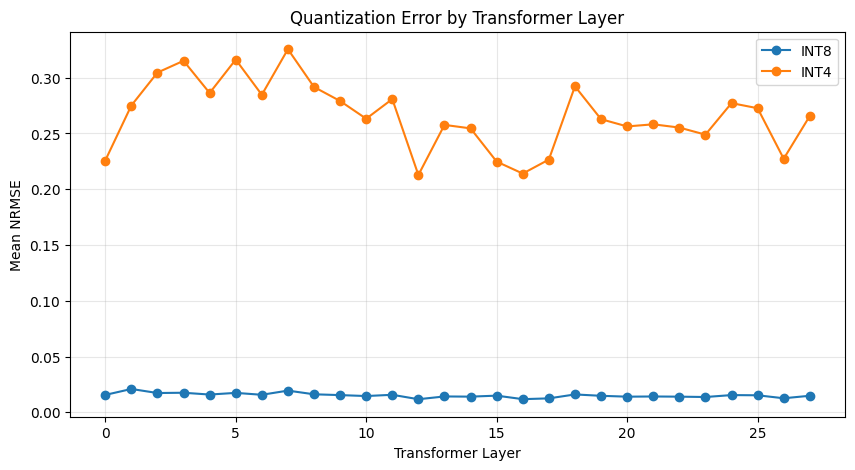

In [10]:
import matplotlib.pyplot as plt


# --------------------------------------------------
# Average NRMSE by transformer layer
# --------------------------------------------------

layer_error = (
    quant_df
    .groupby(["layer", "precision"])
    ["NRMSE"]
    .mean()
    .reset_index()
)

display(layer_error.head())


plt.figure(figsize=(10, 5))

for precision in ["INT8", "INT4"]:

    data = layer_error[
        layer_error["precision"] == precision
    ]

    plt.plot(
        data["layer"],
        data["NRMSE"],
        marker="o",
        label=precision
    )

plt.xlabel("Transformer Layer")
plt.ylabel("Mean NRMSE")
plt.title("Quantization Error by Transformer Layer")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

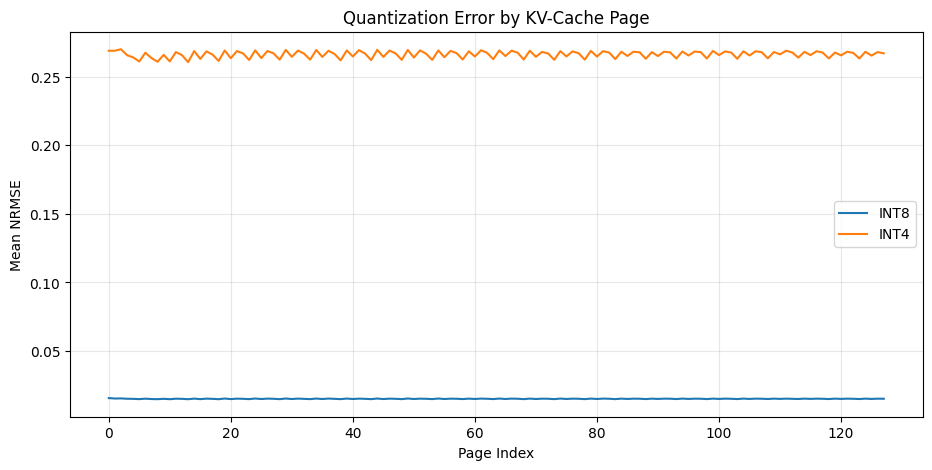

In [11]:
# --------------------------------------------------
# Average NRMSE by page position
# --------------------------------------------------

page_error = (
    quant_df
    .groupby(["page", "precision"])
    ["NRMSE"]
    .mean()
    .reset_index()
)


plt.figure(figsize=(11, 5))

for precision in ["INT8", "INT4"]:

    data = page_error[
        page_error["precision"] == precision
    ]

    plt.plot(
        data["page"],
        data["NRMSE"],
        label=precision
    )

plt.xlabel("Page Index")
plt.ylabel("Mean NRMSE")
plt.title("Quantization Error by KV-Cache Page")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
# --------------------------------------------------
# Find pages with highest / lowest INT4 error
# --------------------------------------------------

int4_page_error = (
    page_error[
        page_error["precision"] == "INT4"
    ]
    .sort_values(
        "NRMSE",
        ascending=False
    )
)


print("Highest-error INT4 pages:")
display(int4_page_error.head(10))


print("\nLowest-error INT4 pages:")
display(int4_page_error.tail(10))

Highest-error INT4 pages:


,page,precision,NRMSE
4,2,INT4,0.269987
88,44,INT4,0.269561
58,29,INT4,0.269513
68,34,INT4,0.269457
98,49,INT4,0.269435
82,41,INT4,0.269310
122,61,INT4,0.269239
48,24,INT4,0.269152
78,39,INT4,0.269116
102,51,INT4,0.269114



Lowest-error INT4 pages:


,page,precision,NRMSE
96,48,INT4,0.262246
106,53,INT4,0.262214
46,23,INT4,0.262145
86,43,INT4,0.262032
76,38,INT4,0.261850
36,18,INT4,0.261441
20,10,INT4,0.261083
10,5,INT4,0.261059
16,8,INT4,0.260865
26,13,INT4,0.260597


Quantization Error Across Layers and Pages

Quantization error was analyzed across all transformer layers and KV-cache pages. The results show noticeably greater variation across transformer layers than across token pages. In particular, INT4 NRMSE varies substantially between layers, while the average NRMSE across page positions remains nearly constant.

This indicates that numerical quantization difficulty is more layer-dependent than position-dependent for the analyzed sequence. However, reconstruction error should not be interpreted as model importance: a page with low quantization error may still be important to attention, while a page with high reconstruction error may have little influence on the output.

Therefore, the adaptive page policy should not rely solely on local quantization error. Later experiments will consider signals such as attention importance, prefix protection, and recency. The current page-position analysis is also based on a repeated synthetic sequence, so final model-quality conclusions will be evaluated on natural text using perplexity.

#####Different layers have different numerical quantization behavior
#####Quantization error varies much more by layer than by page position

#### Quantization error $\neq$ importance to the model.

#7. Memory savings of FP16, INT8, and INT4

In [13]:
# --------------------------------------------------
# Memory cost of uniform quantization
# --------------------------------------------------

num_pages = math.ceil(
    ANALYSIS_SEQ_LEN / PAGE_SIZE
)

# Total number of KV values in the cache
total_kv_elements = 0

for layer in fp16_cache.layers:
    total_kv_elements += layer.keys.numel()
    total_kv_elements += layer.values.numel()


# --------------------------------------------------
# FP16 baseline
# --------------------------------------------------

fp16_payload_bytes = (
    total_kv_elements * 2
)   # 16 bits = 2 bytes


# --------------------------------------------------
# Quantization scale overhead
#
# One FP32 scale for:
#   each layer
#   each page
#   K and V separately
# --------------------------------------------------

num_scales = (
    num_layers
    * num_pages
    * 2
)

bytes_per_scale = 4   # FP32

scale_overhead_bytes = (
    num_scales * bytes_per_scale
)


# --------------------------------------------------
# INT8
# --------------------------------------------------

int8_payload_bytes = (
    total_kv_elements * 1
)   # 8 bits = 1 byte

int8_total_bytes = (
    int8_payload_bytes
    + scale_overhead_bytes
)


# --------------------------------------------------
# INT4
#
# Assumes true packed 4-bit storage:
# two INT4 values per byte.
# --------------------------------------------------

int4_payload_bytes = (
    total_kv_elements / 2
)

int4_total_bytes = (
    int4_payload_bytes
    + scale_overhead_bytes
)


# --------------------------------------------------
# Build comparison table
# --------------------------------------------------

memory_df = pd.DataFrame([
    {
        "Precision": "FP16",
        "Payload (MiB)": fp16_payload_bytes / 1024**2,
        "Scale Overhead (KiB)": 0,
        "Total Memory (MiB)": fp16_payload_bytes / 1024**2,
        "Memory Saving (%)": 0.0,
    },
    {
        "Precision": "INT8",
        "Payload (MiB)": int8_payload_bytes / 1024**2,
        "Scale Overhead (KiB)": scale_overhead_bytes / 1024,
        "Total Memory (MiB)": int8_total_bytes / 1024**2,
        "Memory Saving (%)":
            100 * (
                1 - int8_total_bytes / fp16_payload_bytes
            ),
    },
    {
        "Precision": "INT4",
        "Payload (MiB)": int4_payload_bytes / 1024**2,
        "Scale Overhead (KiB)": scale_overhead_bytes / 1024,
        "Total Memory (MiB)": int4_total_bytes / 1024**2,
        "Memory Saving (%)":
            100 * (
                1 - int4_total_bytes / fp16_payload_bytes
            ),
    },
])

display(memory_df)


print("Total KV elements:", f"{total_kv_elements:,}")
print("Number of quantization scales:", num_scales)
print(
    "Scale metadata:",
    f"{scale_overhead_bytes / 1024:.2f} KiB"
)

,Precision,Payload (MiB),Scale Overhead (KiB),Total Memory (MiB),Memory Saving (%)
0,FP16,56.0,0.0,56.000000,0.000000
1,INT8,28.0,28.0,28.027344,49.951172
2,INT4,14.0,28.0,14.027344,74.951172


Total KV elements: 29,360,128
Number of quantization scales: 7168
Scale metadata: 28.00 KiB


Uniform Quantization Memory Cost

The 2048-token FP16 KV cache contains 29,360,128 values and requires 56 MiB. Uniform INT8 reduces the theoretical cache size to approximately 28.03 MiB, corresponding to a 49.95% memory saving, while packed INT4 reduces it to approximately 14.03 MiB, corresponding to a 74.95% saving.

Each K/V page uses an independent FP32 scale, requiring 7,168 scales in total. Their combined metadata cost is only 28 KiB, making the scale overhead negligible for the selected 16-token page size.

The INT4 memory result assumes true packed 4-bit storage. In the current PyTorch prototype, INT4 values are temporarily represented using an int8 container; therefore, the reported INT4 memory is the theoretical storage requirement of a packed implementation.

Quantization Scale Metadata

Quantization is performed independently for each layer, page, and tensor type (Key or Value). Therefore, every K page and V page receives its own FP32 scale. This allows tensors with different numerical ranges to use the available integer range efficiently instead of sharing a potentially unsuitable global scale.

With 28 transformer layers, 128 token pages, and separate scales for Key and Value tensors, the cache requires

28×128×2=7168

FP32 scale values. At 4 bytes per FP32 value, the total scale metadata requires only

7168×4=28672 bytes=28 KiB.

This corresponds to approximately 0.10% overhead for INT8 and 0.20% for packed INT4, so the scale metadata is negligible relative to the compressed KV-cache payload. (scale metadata is tiny compared with the KV payload)

#8. Save and summarize

In [15]:
import json

# --------------------------------------------------
# Helper for extracting summary values
# --------------------------------------------------

def get_error_metric(precision, tensor, metric):
    row = summary[
        (summary["precision"] == precision) &
        (summary["tensor"] == tensor)
    ]

    return float(row.iloc[0][metric])


def get_memory_metric(precision, metric):
    row = memory_df[
        memory_df["Precision"] == precision
    ]

    return float(row.iloc[0][metric])


# --------------------------------------------------
# Compact experiment summary
# --------------------------------------------------

uniform_quantization_summary = {
    "model": MODEL_ID,
    "sequence_length": ANALYSIS_SEQ_LEN,
    "page_size": PAGE_SIZE,
    "num_layers": num_layers,
    "num_pages": num_pages,

    "quantization_method":
        "symmetric per-layer, per-page, per-K/V uniform quantization",

    "num_measurements": len(quant_df),

    # Mean normalized reconstruction error
    "int8_key_mean_nrmse":
        get_error_metric("INT8", "Key", "Mean_NRMSE"),

    "int8_value_mean_nrmse":
        get_error_metric("INT8", "Value", "Mean_NRMSE"),

    "int4_key_mean_nrmse":
        get_error_metric("INT4", "Key", "Mean_NRMSE"),

    "int4_value_mean_nrmse":
        get_error_metric("INT4", "Value", "Mean_NRMSE"),

    # Memory
    "fp16_memory_mib":
        get_memory_metric("FP16", "Total Memory (MiB)"),

    "int8_memory_mib":
        get_memory_metric("INT8", "Total Memory (MiB)"),

    "int4_memory_mib_packed":
        get_memory_metric("INT4", "Total Memory (MiB)"),

    "int8_memory_saving_percent":
        get_memory_metric("INT8", "Memory Saving (%)"),

    "int4_memory_saving_percent":
        get_memory_metric("INT4", "Memory Saving (%)"),

    "scale_metadata_kib":
        scale_overhead_bytes / 1024,
}


# --------------------------------------------------
# Print compact summary
# --------------------------------------------------

print("Uniform KV Quantization Summary")
print("-------------------------------")

for key, value in uniform_quantization_summary.items():
    print(f"{key}: {value}")


# --------------------------------------------------
# Save results
# --------------------------------------------------

quant_df.to_csv(
    "uniform_quantization_all_pages.csv",
    index=False
)

summary.to_csv(
    "uniform_quantization_error_summary.csv",
    index=False
)

memory_df.to_csv(
    "uniform_quantization_memory.csv",
    index=False
)

with open(
    "uniform_quantization_summary.json",
    "w"
) as f:
    json.dump(
        uniform_quantization_summary,
        f,
        indent=4
    )


print("\nSaved:")
print("  uniform_quantization_all_pages.csv")
print("  uniform_quantization_error_summary.csv")
print("  uniform_quantization_memory.csv")
print("  uniform_quantization_summary.json")

Uniform KV Quantization Summary
-------------------------------
model: Qwen/Qwen2.5-1.5B
sequence_length: 2048
page_size: 16
num_layers: 28
num_pages: 128
quantization_method: symmetric per-layer, per-page, per-K/V uniform quantization
num_measurements: 14336
int8_key_mean_nrmse: 0.016091242796730694
int8_value_mean_nrmse: 0.01433007686329619
int4_key_mean_nrmse: 0.27378752138361884
int4_value_mean_nrmse: 0.2587422350306226
fp16_memory_mib: 56.0
int8_memory_mib: 28.02734375
int4_memory_mib_packed: 14.02734375
int8_memory_saving_percent: 49.951171875
int4_memory_saving_percent: 74.951171875
scale_metadata_kib: 28.0

Saved:
  uniform_quantization_all_pages.csv
  uniform_quantization_error_summary.csv
  uniform_quantization_memory.csv
  uniform_quantization_summary.json
